# Session 10 lab: Which spending needs review?

<p class="lead">
Build a budget-versus-actual comparison that adds up, find the exceptions that matter, untangle a duplicated invoice and its reversal, fix a colleague's broken analysis, and recommend three lines for the monthly expense review.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/10_finance_budget_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

> *Finance partner: "I can take about a dozen lines into next month's expense review. I need a list I can defend: which department and account lines, why each one, and what to ask. And please make sure the numbers reconcile, last time a report double-counted the budget."*

> **About the data**
>
> `finance_actuals.csv` and `finance_budget.csv` are **synthetic** teaching data generated by the course: a fictional company's monthly **management expense** view for calendar 2025. No real company, person or supplier is described. Amounts are in neutral **currency units**. This is not a financial statement: there is no revenue, no balance sheet and no audit claim.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G5 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I6 |
| **Challenge** | Debugging and a recommendation | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Check the grain, keys and signs of a posting table and a budget table.
2. Aggregate postings to the budget grain, then outer-join with an indicator.
3. Reconcile the result to both sources.
4. Compute variance, favourability and variance % correctly, including zero and unknown budgets.
5. Rank exceptions by amount and by percentage, and explain the difference.
6. Recognise a duplicate posting and its reversal behind a "favourable" month.
7. Draw a variance chart whose colours are colour-blind-safe and labelled.
8. Recommend review priorities with reasons and follow-up questions.

**Evidence you keep:** a variance view, a reconciliation note and a short recommendation.

---

## Before you start

- Read the [Session 10 lecture](10_finance_budget_lecture.md).
- Re-read [How statistics can mislead](../foundations/misleading-statistics.md) and [Visual design](../foundations/visual-design.md).

---

## Guided practice

### G1 (Core): Load the data and check keys and signs

Run the setup cell, then the cell that loads both tables.

In [1]:
# Finance data setup (synthetic). Run this cell first.
# Downloads the course's synthetic finance data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

FINANCE_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/finance-v1/"
FINANCE_SHA256 = {
    "finance_actuals.csv": "3aeb2773990f86c21a1536b8854d7290794315e8bc872420c2e5df77151ac7fd",
    "finance_budget.csv": "238dbec8e7e80a61068c12c48280ff4f9de91198879ee295366774f530efad60",
}
FINANCE_DIR = os.environ.get("COURSE_FINANCE_DIR", "")


def load_finance(name):
    """Load one finance-v1 file: 'finance_actuals.csv' or 'finance_budget.csv'."""
    if FINANCE_DIR:
        with open(os.path.join(FINANCE_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(FINANCE_URL + name).read()
    if hashlib.sha256(data).hexdigest() != FINANCE_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["month"], keep_default_na=False,
                       na_values={"amount": [""], "budget": [""]})


print("Finance setup complete.")

Finance setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

# Colour-blind-safe pair used for every variance chart in this session.
# Blue = favourable (under budget), orange = unfavourable (over budget). Always add a legend too.
FAVOURABLE, UNFAVOURABLE = "#2a78d6", "#eb6834"

actuals = load_finance("finance_actuals.csv")
budget = load_finance("finance_budget.csv")
print("Postings:", len(actuals), "| budget cells:", len(budget))

Postings: 1378 | budget cells: 432


In [3]:
KEY = ["month", "department_id", "department", "account_id", "account"]

print("posting_id unique:", actuals["posting_id"].is_unique)
print("Budget keys unique:", not budget.duplicated(KEY).any())
print("Any negative budget:", (budget["budget"] < 0).any(), "| zero budgets:", (budget["budget"] == 0).sum())
print("Missing amounts:", actuals["amount"].isna().sum(), "| missing budgets:", budget["budget"].isna().sum())
actuals.groupby("posting_type")["amount"].agg(postings="count", total="sum", smallest="min", largest="max")

posting_id unique: True
Budget keys unique: True
Any negative budget: False | zero budgets: 3
Missing amounts: 0 | missing budgets: 0


,postings,total,smallest,largest
posting_type,,,,
credit,1,"-2,000.00","-2,000.00","-2,000.00"
expense,1376,"6,250,301.60",34.48,"110,814.44"
reversal,1,"-6,500.00","-6,500.00","-6,500.00"


Write down in your evidence log: the grain and key of each table, how many postings are credits or reversals, and the sign convention (positive = expense, negative = credit or reversal).

### G2 (Core): Aggregate postings to the budget grain

> **Your turn:** change the code in the next cell and run it again.

In [4]:
# 1. Run the cell. How many actual cells are there, compared with posting rows?
# 2. Check: is the total of `actual` exactly equal to the total of the posting amounts?
# 3. Change "sum" to "max" for actual and run again. Why would that be wrong? Change it back.
actual_cells = actuals.groupby(KEY, as_index=False).agg(actual=("amount", "sum"),
                                                        postings=("posting_id", "count"))
print("Posting rows:", len(actuals), "-> actual cells:", len(actual_cells))
print(f"Sum of postings:     {actuals['amount'].sum():,.2f}")
print(f"Sum of actual cells: {actual_cells['actual'].sum():,.2f}")
actual_cells.head()

Posting rows: 1378 -> actual cells: 431
Sum of postings:     6,241,801.60
Sum of actual cells: 6,241,801.60


,month,department_id,department,account_id,account,actual,postings
0,2025-01-01,D01,Sales,A100,Salaries and wages,"85,470.10",2
1,2025-01-01,D01,Sales,A200,Travel,"6,843.41",6
2,2025-01-01,D01,Sales,A300,Software subscriptions,"3,767.03",2
3,2025-01-01,D01,Sales,A400,Facilities,"5,512.62",1
4,2025-01-01,D01,Sales,A500,Professional services,"2,071.17",3


### G3 (Core): Outer join with an indicator

Join the actual cells to the budget **one-to-one**, keeping cells from both sides, and record where each came from.

In [5]:
var = actual_cells.merge(budget, on=KEY, how="outer", indicator=True, validate="one_to_one")
var["match"] = var["_merge"].astype(str).map({"both": "actual and budget",
                                              "left_only": "actual only",
                                              "right_only": "budget only"})
var = var.drop(columns="_merge")

var["postings"] = var["postings"].fillna(0).astype(int)
var["actual"] = var["actual"].fillna(0)            # budget-only: no postings, so actual = 0
var["budget_status"] = np.select([var["budget"].isna(), var["budget"] == 0],
                                 ["unknown budget", "approved zero budget"], default="positive budget")

var["variance"] = var["actual"] - var["budget"]    # NaN when the budget is unknown
var["variance_pct"] = np.where(var["budget"] > 0, var["variance"] / var["budget"], np.nan)
var["direction"] = np.select([var["budget"].isna(), var["variance"] > 0, var["variance"] < 0],
                             ["not assessed (budget unknown)", "unfavourable", "favourable"], default="on budget")
var.loc[(var["budget"] == 0) & (var["actual"] > 0), "direction"] = "unbudgeted spend against zero"

pd.crosstab(var["match"], var["budget_status"])

budget_status,approved zero budget,positive budget,unknown budget
match,,,
actual and budget,1,424,0
actual only,0,0,6
budget only,2,5,0


> **Why fill `actual` with 0 but not `budget`?**
>
> A budget-only cell has no postings, so its spending really is 0 (once finance confirms the month's postings are complete). An actual-only cell has no budget **row**, so its budget is **unknown**. Filling it with 0 would invent an overspend.

### G4 (Core): Reconcile

This function compares any variance table with the two sources. You will reuse it in the challenge.

In [6]:
def reconcile(table, label):
    """Compare a variance table with the two source tables and print PASS or FAIL for each check."""
    all_keys = pd.concat([actuals[KEY], budget[KEY]]).drop_duplicates()
    checks = [
        ("One row per (month, department, account)", not table.duplicated(KEY).any()),
        ("Every key from either source is present", len(table) == len(all_keys)),
        ("Actual total = signed posting total", abs(table["actual"].sum() - actuals["amount"].sum()) < 0.005),
        ("Budget total = total of unique budget cells", abs(table["budget"].sum() - budget["budget"].sum()) < 0.005),
    ]
    print(f"Reconciliation: {label}")
    print(f"  rows {len(table)} vs keys {len(all_keys)}")
    print(f"  actual {table['actual'].sum():,.2f} vs postings {actuals['amount'].sum():,.2f}")
    print(f"  budget {table['budget'].sum():,.2f} vs budget cells {budget['budget'].sum():,.2f}")
    for name, ok in checks:
        print(f"  {'PASS' if ok else 'FAIL'}  {name}")


reconcile(var, "my variance table")

Reconciliation: my variance table
  rows 438 vs keys 438
  actual 6,241,801.60 vs postings 6,241,801.60
  budget 6,133,000.00 vs budget cells 6,133,000.00
  PASS  One row per (month, department, account)
  PASS  Every key from either source is present
  PASS  Actual total = signed posting total
  PASS  Budget total = total of unique budget cells


Copy the four PASS lines and the two totals into your evidence log. This is the start of your **reconciliation note**.

### G5 (Core): The monthly variance table

The finance partner reviews month by month. Build one row per month for the **comparable scope** (cells with a known budget), and show the unknown-budget spending in its own column so it is visible but not mixed in.

> **Your turn:** change the code in the next cell and run it again.

In [7]:
# 1. Run the cell. Which month has the largest variance? Is it favourable or unfavourable?
# 2. Change department to "Sales", then "Technology". Which months stand out?
# 3. Why is variance_pct recomputed from the monthly totals rather than averaged from the cells?
department = "All"

scope = var if department == "All" else var[var["department"] == department]
comparable = scope[scope["budget_status"] != "unknown budget"]
monthly = comparable.groupby("month")[["actual", "budget"]].sum()
monthly["variance"] = monthly["actual"] - monthly["budget"]
monthly["variance_pct"] = monthly["variance"] / monthly["budget"]
monthly["unknown_budget_actual"] = scope[scope["budget_status"] == "unknown budget"].groupby("month")["actual"].sum()
monthly["unknown_budget_actual"] = monthly["unknown_budget_actual"].fillna(0)

total = monthly[["actual", "budget", "unknown_budget_actual"]].sum()
print(f"{department}: comparable actual {total['actual']:,.2f} | budget {total['budget']:,.2f} | "
      f"variance {total['actual'] - total['budget']:+,.2f} ({(total['actual'] - total['budget']) / total['budget']:+.1%}) "
      f"| unknown-budget actual {total['unknown_budget_actual']:,.2f}")
monthly.assign(variance_pct=monthly["variance_pct"].map("{:+.1%}".format))

All: comparable actual 6,208,423.43 | budget 6,133,000.00 | variance +75,423.43 (+1.2%) | unknown-budget actual 33,378.17


,actual,budget,variance,variance_pct,unknown_budget_actual
month,,,,,
2025-01-01,"506,329.01","504,400.00","1,929.01",+0.4%,0.00
2025-02-01,"504,289.27","506,500.00","-2,210.73",-0.4%,0.00
2025-03-01,"519,680.15","512,400.00","7,280.15",+1.4%,0.00
2025-04-01,"520,421.62","515,200.00","5,221.62",+1.0%,0.00
2025-05-01,"531,350.70","517,300.00","14,050.70",+2.7%,0.00
2025-06-01,"514,392.30","511,300.00","3,092.30",+0.6%,0.00
2025-07-01,"514,374.78","503,400.00","10,974.78",+2.2%,"2,383.57"
2025-08-01,"505,260.27","503,400.00","1,860.27",+0.4%,"4,911.66"
2025-09-01,"522,861.32","515,200.00","7,661.32",+1.5%,"3,531.16"


---

## Independent tasks

### I1 (Core): Top exceptions by amount and by percentage

> **Your turn:** change the code in the next cell and run it again.

In [8]:
# 1. Run the cell. Compare the two lists. Which cells appear in both?
# 2. Change rank_by to "variance_pct". Which small cells rise to the top? Are they worth a meeting?
# 3. Change n to 15. Does the % list become dominated by one department or account?
rank_by = "variance"
n = 10

show = ["month", "department", "account", "postings", "actual", "budget", "variance", "variance_pct", "direction"]
known = var.dropna(subset=["variance_pct"])
top = known.sort_values(rank_by, key=abs, ascending=False).head(n)
top[show].assign(variance_pct=top["variance_pct"].map("{:+.0%}".format))

,month,department,account,postings,actual,budget,variance,variance_pct,direction
145,2025-05-01,Sales,Travel,6,"24,385.85","12,000.00","12,385.85",+103%,unfavourable
120,2025-04-01,Operations,Salaries and wages,2,"133,955.61","124,000.00","9,955.61",+8%,unfavourable
320,2025-09-01,People,Training,5,"12,300.00","4,100.00","8,200.00",+200%,unfavourable
181,2025-06-01,Sales,Travel,4,"2,274.94","9,200.00","-6,925.06",-75%,favourable
84,2025-03-01,Operations,Salaries and wages,2,"130,080.34","124,000.00","6,080.34",+5%,unfavourable
12,2025-01-01,Operations,Salaries and wages,2,"129,805.69","124,000.00","5,805.69",+5%,unfavourable
271,2025-08-01,Technology,Salaries and wages,2,"65,634.86","71,000.00","-5,365.14",-8%,favourable
345,2025-10-01,Technology,Salaries and wages,2,"75,725.19","71,000.00","4,725.19",+7%,unfavourable
327,2025-10-01,Sales,Salaries and wages,2,"86,710.43","82,000.00","4,710.43",+6%,unfavourable
419,2025-12-01,Technology,Salaries and wages,2,"75,527.08","71,000.00","4,527.08",+6%,unfavourable


In your evidence log, name one cell that ranks high **by amount but not by %**, and one that ranks high **by % but not by amount**. Say in one sentence why each might, or might not, deserve a review.

### I2 (Core): Actual-only, budget-only and zero-budget cells

> **Your turn:** change the code in the next cell and run it again.

In [9]:
# 1. Run the cell. Which account has spending but no budget? In which months?
# 2. Change status to "approved zero budget". Which zero-budget cell has spending, and why is there no %?
# 3. Change status to "budget only" (it filters on the match column). What questions would you ask about these cells?
status = "unknown budget"

if status == "budget only":
    cells = var[var["match"] == "budget only"]
else:
    cells = var[var["budget_status"] == status]
print(f"{status}: {len(cells)} cells | actual {cells['actual'].sum():,.2f} | "
      f"budget known for {cells['budget'].notna().sum()} of {len(cells)} cells, total {cells['budget'].sum():,.2f}")
cells[["month", "department", "account", "postings", "actual", "budget", "variance", "direction"]]

unknown budget: 6 cells | actual 33,378.17 | budget known for 0 of 6 cells, total 0.00


,month,department,account,postings,actual,budget,variance,direction
240,2025-07-01,Technology,Cloud hosting,2,"2,383.57",NaN,NaN,not assessed (budget unknown)
277,2025-08-01,Technology,Cloud hosting,2,"4,911.66",NaN,NaN,not assessed (budget unknown)
314,2025-09-01,Technology,Cloud hosting,2,"3,531.16",NaN,NaN,not assessed (budget unknown)
351,2025-10-01,Technology,Cloud hosting,2,"8,911.91",NaN,NaN,not assessed (budget unknown)
388,2025-11-01,Technology,Cloud hosting,2,"4,266.88",NaN,NaN,not assessed (budget unknown)
425,2025-12-01,Technology,Cloud hosting,1,"9,372.99",NaN,NaN,not assessed (budget unknown)


> **Hint**
>
> A budget-only cell shows a variance equal to minus its budget, which reads as "100% favourable". Is an unused training budget for five months in a row good news? What else could it mean?

### I3 (Core): The Sales travel story

Sales travel looks badly over budget in one month and well under in the next. Find out why from the postings.

> **Your turn:** change the code in the next cell and run it again.

In [10]:
# 1. Run the cell. In which month is the variance most unfavourable, and in which most favourable?
# 2. Change account to "Professional services" and department to "People". Which month has a negative posting?
# 3. Set months to ["2025-09-01", "2025-10-01", "2025-11-01"] for People professional services.
department, account = "Sales", "Travel"
months = ["2025-05-01", "2025-06-01"]

line = var[(var["department"] == department) & (var["account"] == account)].set_index("month")
display(line[["postings", "actual", "budget", "variance", "direction"]])

postings = actuals[(actuals["department"] == department) & (actuals["account"] == account)
                   & actuals["month"].isin(pd.to_datetime(months))]
postings[["posting_id", "posting_date", "month", "amount", "posting_type", "reference_posting_id", "description"]]

,postings,actual,budget,variance,direction
month,,,,,
2025-01-01,6,"6,843.41","6,400.00",443.41,unfavourable
2025-02-01,3,"6,959.24","7,400.00",-440.76,favourable
2025-03-01,2,"10,684.76","10,100.00",584.76,unfavourable
2025-04-01,1,"10,213.47","11,000.00",-786.53,favourable
2025-05-01,6,"24,385.85","12,000.00","12,385.85",unfavourable
2025-06-01,4,"2,274.94","9,200.00","-6,925.06",favourable
2025-07-01,5,"5,557.23","5,500.00",57.23,unfavourable
2025-08-01,3,"5,668.55","5,500.00",168.55,unfavourable
2025-09-01,5,"11,940.45","11,000.00",940.45,unfavourable


,posting_id,posting_date,month,amount,posting_type,reference_posting_id,description
483,P25-00484,2025-05-14,2025-05-01,"2,123.44",expense,,Travel - Sales
486,P25-00487,2025-05-15,2025-05-01,"1,492.03",expense,,Travel - Sales
500,P25-00501,2025-05-17,2025-05-01,"6,818.31",expense,,Travel - Sales
537,P25-00538,2025-05-25,2025-05-01,952.07,expense,,Travel - Sales
551,P25-00552,2025-05-28,2025-05-01,"6,500.00",expense,,Conference travel invoice
552,P25-00553,2025-05-28,2025-05-01,"6,500.00",expense,,Conference travel invoice
600,P25-00601,2025-06-07,2025-06-01,"4,965.34",expense,,Travel - Sales
610,P25-00611,2025-06-09,2025-06-01,"-6,500.00",reversal,P25-00553,Reversal of duplicated May conference invoice
667,P25-00668,2025-06-25,2025-06-01,"2,431.46",expense,,Travel - Sales
669,P25-00670,2025-06-26,2025-06-01,"1,378.14",expense,,Travel - Sales


Now check for **duplicate postings**: rows identical in everything except `posting_id`. Then find what the reversal points to.

In [11]:
same_content = [c for c in actuals.columns if c != "posting_id"]
dupes = actuals[actuals.duplicated(same_content, keep=False)]
print("Postings that have an identical twin:", len(dupes))
display(dupes[["posting_id", "posting_date", "department", "account", "amount", "description"]])

reversals = actuals[actuals["posting_type"] == "reversal"]
print("Reversals and the posting each one cancels:")
reversals.merge(actuals, left_on="reference_posting_id", right_on="posting_id", suffixes=("", "_reversed"))[
    ["posting_id", "month", "amount", "posting_id_reversed", "month_reversed", "amount_reversed"]]

Postings that have an identical twin: 2


,posting_id,posting_date,department,account,amount,description
551,P25-00552,2025-05-28,Sales,Travel,"6,500.00",Conference travel invoice
552,P25-00553,2025-05-28,Sales,Travel,"6,500.00",Conference travel invoice


Reversals and the posting each one cancels:


,posting_id,month,amount,posting_id_reversed,month_reversed,amount_reversed
0,P25-00611,2025-06-01,"-6,500.00",P25-00553,2025-05-01,"6,500.00"


Write three sentences in your evidence log:

1. What happened in May, using the posting IDs.
2. What happened in June, and why June's favourable variance is **not** good travel management.
3. What May and June look like **together**, and what control you would suggest to finance (for example, a duplicate-invoice check before posting).

### I4 (Core): A variance chart that cannot be misread

Draw the annual variance for each department (comparable cells). Colours: **orange = over budget (unfavourable)** and **blue = under budget (favourable)**. This pair is distinguishable for the most common forms of colour blindness, unlike red and green, and the legend and value labels mean nobody depends on colour alone.

> **Your turn:** change the code in the next cell and run it again.

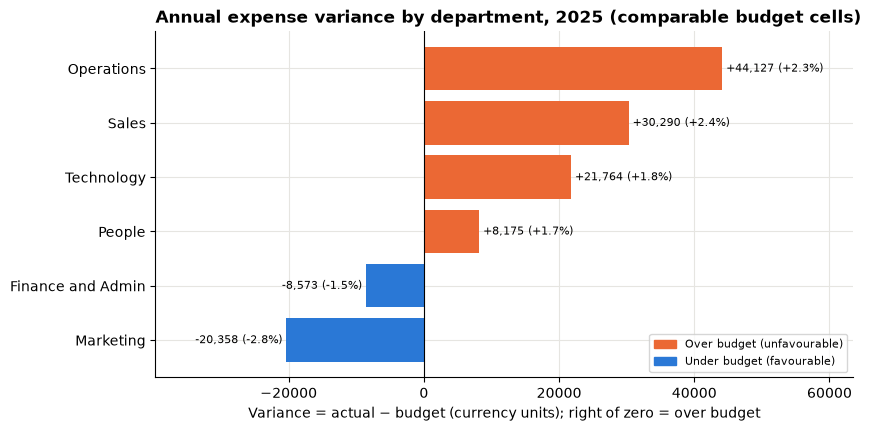

Not in the chart: 33,378.17 of spending with no budget (reported separately).


In [12]:
# 1. Run the cell. Which departments are over budget for the year? Which are under?
# 2. Change group to "account". Which account drives most of the overspend?
# 3. Add a sentence-style title that states the main message instead of just describing the chart.
group = "department"

annual = var[var["budget_status"] != "unknown budget"].groupby(group)[["actual", "budget"]].sum()
annual["variance"] = annual["actual"] - annual["budget"]
annual["variance_pct"] = annual["variance"] / annual["budget"]
annual = annual.sort_values("variance")

fig, ax = plt.subplots(figsize=(9, 4.5))
colours = [UNFAVOURABLE if v > 0 else FAVOURABLE for v in annual["variance"]]
ax.barh(annual.index, annual["variance"], color=colours)
ax.axvline(0, color="black", linewidth=0.8)
for y, (v, p) in enumerate(zip(annual["variance"], annual["variance_pct"])):
    ax.text(v, y, f" {v:+,.0f} ({p:+.1%}) ", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.set_title(f"Annual expense variance by {group}, 2025 (comparable budget cells)")
ax.set_xlabel("Variance = actual − budget (currency units); right of zero = over budget")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=UNFAVOURABLE), plt.Rectangle((0, 0), 1, 1, color=FAVOURABLE)],
          labels=["Over budget (unfavourable)", "Under budget (favourable)"], fontsize=8, loc="lower right")
ax.margins(x=0.3)
plt.show()

unknown_actual = var.loc[var["budget_status"] == "unknown budget", "actual"].sum()
print(f"Not in the chart: {unknown_actual:,.2f} of spending with no budget (reported separately).")

Keep this chart, with its note about unknown-budget spending, as your **variance view**.

### I5 (Stretch): Department × account view with materiality flags

Build the annual department × account table and flag lines with a rule like the lecture's. The limits are higher than in the lecture because annual variances are bigger than monthly ones. Then look at the monthly pattern of one flagged line.

> **Your turn:** change the code in the next cell and run it again.

,,actual,budget,variance,variance_pct,flag
department,account,,,,,
Operations,Salaries and wages,"1,528,096.20","1,488,000.00","40,096.20",+2.7%,amount
Technology,Software subscriptions,"215,898.99","184,800.00","31,098.99",+16.8%,amount and %
Sales,Salaries and wages,"1,006,341.26","984,000.00","22,341.26",+2.3%,amount
People,Training,"57,876.64","49,200.00","8,676.64",+17.6%,%
Marketing,Training,"9,044.44","15,600.00","-6,555.56",-42.0%,%
Finance and Admin,Training,"9,910.86","8,100.00","1,810.86",+22.4%,%


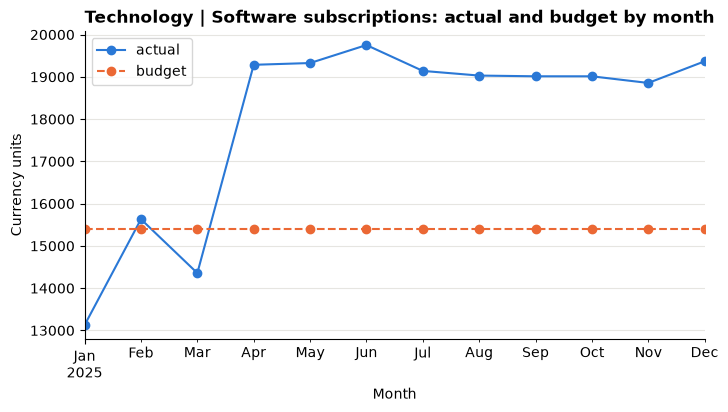

In [13]:
# 1. Run the cell. How many lines are flagged? Which are flagged by amount, which by %?
# 2. Change AMOUNT_LIMIT to 10000 and PCT_LIMIT to 0.15. How does the list change? Who should choose these limits?
# 3. Change line_to_plot to one of the flagged lines. Is the variance spread across the year or concentrated in a few months?
AMOUNT_LIMIT = 20000
PCT_LIMIT = 0.15
MIN_AMOUNT_FOR_PCT = 1000
line_to_plot = ("Technology", "Software subscriptions")

view = var[var["budget_status"] != "unknown budget"].groupby(["department", "account"])[["actual", "budget"]].sum()
view["variance"] = view["actual"] - view["budget"]
view["variance_pct"] = np.where(view["budget"] > 0, view["variance"] / view["budget"], np.nan)
big_amount = view["variance"].abs() >= AMOUNT_LIMIT
big_pct = (view["variance_pct"].abs() >= PCT_LIMIT) & (view["variance"].abs() >= MIN_AMOUNT_FOR_PCT)
view["flag"] = np.select([big_amount & big_pct, big_amount, big_pct], ["amount and %", "amount", "%"], default="")
flagged = view[view["flag"] != ""].sort_values("variance", key=abs, ascending=False)
display(flagged.assign(variance_pct=flagged["variance_pct"].map("{:+.1%}".format)))

one = var[(var["department"] == line_to_plot[0]) & (var["account"] == line_to_plot[1])].set_index("month")
ax = one[["actual", "budget"]].plot(marker="o", style=["-", "--"])
ax.set_title(f"{line_to_plot[0]} | {line_to_plot[1]}: actual and budget by month")
ax.set_xlabel("Month")
ax.set_ylabel("Currency units")
plt.show()

### I6 (Stretch): Why the average of percentages misleads

Compute the company's variance % three ways and explain the differences.

In [14]:
comparable = var[var["budget_status"] != "unknown budget"]
from_totals = (comparable["actual"].sum() - comparable["budget"].sum()) / comparable["budget"].sum()
mean_of_cells = comparable["variance_pct"].mean()
by_dept = comparable.groupby("department")[["actual", "budget"]].sum()
mean_of_depts = ((by_dept["actual"] - by_dept["budget"]) / by_dept["budget"]).mean()

print(f"From comparable totals (correct): {from_totals:+.2%}")
print(f"Mean of department %:             {mean_of_depts:+.2%}")
print(f"Mean of every cell's %:           {mean_of_cells:+.2%}")

From comparable totals (correct): +1.23%
Mean of department %:             +0.67%
Mean of every cell's %:           -0.21%


Which method gives every cell equal weight, regardless of its budget? Which cells pull the mean of cell percentages away from the correct figure? (Look back at I1 sorted by `variance_pct`.)

---

## Challenge

### C1 (Challenge): Debug a colleague's analysis

A colleague sent you three pieces of work. Each runs without an error. Each is wrong. For each one: run the **before** cell, use `reconcile` or the output to explain what is wrong, then fix the code in the **your fix** cell and show the **after** reconciliation.

#### Bug 1: The budget that grew

> *"Budget for the year is huge, so we are way under budget everywhere. Great news!"*

In [15]:
# Colleague's code (before)
colleague_1 = actuals.merge(budget, on=KEY, how="left")
print(f"Colleague's budget total: {colleague_1['budget'].sum():,.2f}")
print(f"Colleague's actual total: {colleague_1['amount'].sum():,.2f}")
print(f"Unique budget cells:      {budget['budget'].sum():,.2f}")

Colleague's budget total: 14,771,900.00
Colleague's actual total: 6,241,801.60
Unique budget cells:      6,133,000.00


> **Your turn:** change the code in the next cell and run it again.

In [16]:
# Your fix (after). Replace the line below with code that builds one row per
# (month, department, account) with columns "actual" and "budget", then reconcile it.
fixed_1 = colleague_1.rename(columns={"amount": "actual"})   # <- still the colleague's grain: replace this line
reconcile(fixed_1, "bug 1 after your fix")

Reconciliation: bug 1 after your fix
  rows 1378 vs keys 438
  actual 6,241,801.60 vs postings 6,241,801.60
  budget 14,771,900.00 vs budget cells 6,133,000.00
  FAIL  One row per (month, department, account)
  FAIL  Every key from either source is present
  PASS  Actual total = signed posting total
  FAIL  Budget total = total of unique budget cells


#### Bug 2: The missing cloud bill

> *"I used a normal merge to keep things simple. Everything matches, no messy blanks."*

In [17]:
# Colleague's code (before)
colleague_2 = (actuals.groupby(KEY, as_index=False)["amount"].sum()
               .rename(columns={"amount": "actual"})
               .merge(budget, on=KEY))                      # default how="inner"
reconcile(colleague_2, "bug 2 before")
print("Accounts in postings but not in the colleague's table:",
      sorted(set(actuals["account"]) - set(colleague_2["account"])))

Reconciliation: bug 2 before
  rows 425 vs keys 438
  actual 6,208,423.43 vs postings 6,241,801.60
  budget 6,126,500.00 vs budget cells 6,133,000.00
  PASS  One row per (month, department, account)
  FAIL  Every key from either source is present
  FAIL  Actual total = signed posting total
  FAIL  Budget total = total of unique budget cells
Accounts in postings but not in the colleague's table: ['Cloud hosting']


> **Your turn:** change the code in the next cell and run it again.

In [18]:
# Your fix (after). Change the merge so no cell is lost, and label where each row came from.
# Remember: a missing actual can become 0, a missing budget must stay unknown.
fixed_2 = colleague_2.copy()                                # <- replace with your corrected merge
reconcile(fixed_2, "bug 2 after your fix")

Reconciliation: bug 2 after your fix
  rows 425 vs keys 438
  actual 6,208,423.43 vs postings 6,241,801.60
  budget 6,126,500.00 vs budget cells 6,133,000.00
  PASS  One row per (month, department, account)
  FAIL  Every key from either source is present
  FAIL  Actual total = signed posting total
  FAIL  Budget total = total of unique budget cells


#### Bug 3: The colours that lie

> *"Blue for positive numbers, orange for negative. Positive is good, right?"*

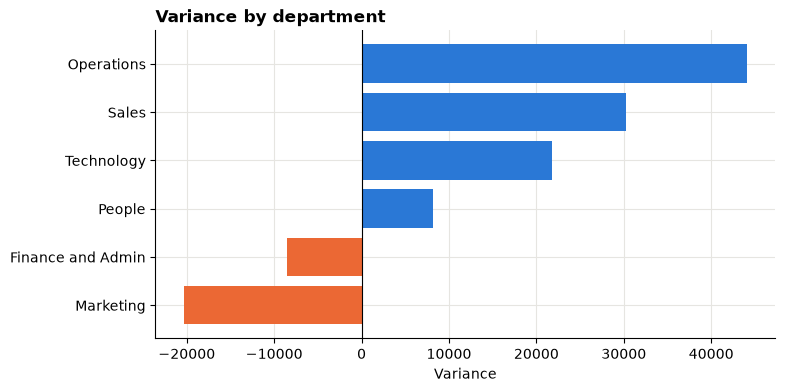

In [19]:
# Colleague's code (before)
dept = var[var["budget_status"] != "unknown budget"].groupby("department")[["actual", "budget"]].sum()
dept["variance"] = dept["actual"] - dept["budget"]
dept = dept.sort_values("variance")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(dept.index, dept["variance"],
        color=[FAVOURABLE if v > 0 else UNFAVOURABLE for v in dept["variance"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Variance by department")
ax.set_xlabel("Variance")
plt.show()

Copy the chart code into a new cell and fix it: correct the colour rule for **expenses**, add a legend that says what each colour means, label the axis with the formula and units, and give it a message title. Check it against the I4 chart.

Write a short **before/after reconciliation note** for each bug: what the colleague's total or chart said, what the corrected version says, and which check proves it.

> **Hint**
>
> Bug 1 is a grain problem; bug 2 is a join-type problem; bug 3 is a sign-convention problem. Only the first two show up in `reconcile`. Charts need their own checks.

### C2 (Challenge): Choose three review priorities

The finance partner can discuss only **three** lines in depth this month. Use everything you have built. The table below collects, for each department × account line, the evidence you need: amounts, percentages and data-quality signals.

In [20]:
negatives = actuals[actuals["amount"] < 0].groupby(["department", "account"]).size()
dupe_lines = dupes.groupby(["department", "account"]).size()
lines = var.groupby(["department", "account"]).agg(
    actual=("actual", "sum"),
    known_budget=("budget", lambda s: s.sum(min_count=1)),     # stays blank when no month has a budget
    months_unknown_budget=("budget_status", lambda s: (s == "unknown budget").sum()),
    months_no_postings=("postings", lambda s: (s == 0).sum()),
    months_over_budget=("variance", lambda s: (s > 0).sum()),
)
lines["variance_known"] = var.groupby(["department", "account"])["variance"].sum(min_count=1)
lines["variance_pct"] = np.where(lines["known_budget"] > 0, lines["variance_known"] / lines["known_budget"], np.nan)
lines["credits_or_reversals"] = negatives.reindex(lines.index).fillna(0).astype(int)
lines["duplicate_postings"] = dupe_lines.reindex(lines.index).fillna(0).astype(int)

lines.sort_values("variance_known", key=abs, ascending=False, na_position="first").head(15)

,,actual,known_budget,months_unknown_budget,months_no_postings,months_over_budget,variance_known,variance_pct,credits_or_reversals,duplicate_postings
department,account,,,,,,,,,
Technology,Cloud hosting,"33,378.17",NaN,6,0,0,NaN,NaN,0,0
Operations,Salaries and wages,"1,528,096.20","1,488,000.00",0,0,10,"40,096.20",0.03,0,0
Technology,Software subscriptions,"215,898.99","184,800.00",0,0,10,"31,098.99",0.17,0,0
Sales,Salaries and wages,"1,006,341.26","984,000.00",0,0,10,"22,341.26",0.02,0,0
Marketing,Salaries and wages,"480,164.76","492,000.00",0,0,2,"-11,835.24",-0.02,0,0
Technology,Salaries and wages,"842,062.76","852,000.00",0,0,5,"-9,937.24",-0.01,0,0
People,Training,"57,876.64","49,200.00",0,0,9,"8,676.64",0.18,0,0
Finance and Admin,Salaries and wages,"363,578.20","372,000.00",0,0,6,"-8,421.80",-0.02,0,0
Marketing,Training,"9,044.44","15,600.00",0,5,5,"-6,555.56",-0.42,0,0


Write your recommendation in your evidence log:

1. **Three priorities**, each with: the line, the evidence (amount, %, months affected), and **why** it is on the list. Use at least two different reasons across the three (for example: a large persistent overspend, a large percentage overspend, spending with no budget, an unused budget, a data-quality problem).
2. For each priority, **one or two follow-up questions** for the department head or finance.
3. **One line you deliberately left off**, and why (for example: large in amount but explained by a reversal, or large in % but tiny in money).

> **Rules for a defensible recommendation**
>
> - Do not treat all underspending as good. An unused budget can mean a cancelled activity, delayed hiring or missing postings.
> - Do not treat a credit or reversal as operating performance.
> - Report spending with no budget separately; do not hide it or call it "100% over".
> - Every number you quote should come from a table that passed `reconcile`.

---

## Validation checklist

- [ ] `posting_id` is unique; budget keys (month, department, account) are unique.
- [ ] Postings were aggregated to the budget grain **before** joining.
- [ ] The join was an **outer** join with `indicator=True` and `validate="one_to_one"`.
- [ ] Actual total equals the signed posting total; budget total equals the unique budget cells.
- [ ] Unknown budgets stay unknown (not 0); their actuals are reported separately.
- [ ] Variance % appears only where budget > 0; zero-budget spending is labelled, not given a %.
- [ ] Expense colours: over budget = unfavourable, under = favourable; colour-blind-safe with a legend.
- [ ] Total percentages are recomputed from totals, never averaged.
- [ ] Credits, reversals and duplicates were checked before calling a month favourable or unfavourable.

---

## Exit ticket

1. Why must postings be aggregated before joining them to budget cells?
2. What is the difference between an unknown budget and an approved zero budget, and how should each appear in a report?
3. A cost line has a variance of −3,000. Is that favourable or unfavourable, and does that automatically mean good performance?
4. Name the two reconciliation totals you check after building a variance table.
5. Why should a small line that is 200% over budget not automatically outrank a large line that is 3% over?

---

## Evidence to keep

- [ ] Your variance view: the I4 chart (and optionally the I5 table), with the note about unknown-budget spending
- [ ] Your reconciliation note: the G4 PASS lines and totals, plus the before/after notes from C1
- [ ] Your Sales travel explanation (I3)
- [ ] Your short recommendation: three review priorities with reasons and follow-up questions (C2)